![Python Banner](../../Image/05_01_tree_based_models.png)



# 1.1 Causal Tree: Single Tree for Heterogeneous Treatment Effects

## Overview

A **Causal Tree** (CT) is a machine learning method introduced by Athey & Imbens (2016) for estimating **Heterogeneous Treatment Effects (HTE)**. Rather than asking "does a treatment work on average?", it asks:

> **"For *whom* does it work, and by *how much*?"**

In a randomized experiment, the Average Treatment Effect (ATE) tells you the mean outcome difference between treated and control groups — but individuals respond differently. For example:

- A drug may help younger patients dramatically while doing nothing for older ones.
- A job training program may benefit people without college degrees but be irrelevant for those with one.

The Causal Tree finds these subgroup differences **automatically** by partitioning the covariate space into regions with meaningfully different treatment effects, called **Conditional Average Treatment Effects (CATEs)**.

### How it differs from a standard regression tree

| | Standard decision tree | Causal tree |
|---|---|---|
| Splits on | Variance in outcome $Y$ | Variance in treatment effect $\tau$ |
| Estimation | In-sample (same data) | Honest (held-out sample) |
| Output | Predicted $\hat{Y}$ | Estimated CATE $\pm$ confidence interval |
| Goal | Prediction | Causal inference |


## Causal Tree Algorithm

The algorithm follows four steps, each building on the last.

### Step 1 — Honest estimation (key innovation)

Standard regression trees use the same data to find splits *and* estimate values in leaves — this leads to overfitting and biased estimates. The Causal Tree avoids this with **honesty**:

- The training data is randomly split into two halves:
  - **Splitting sample** — used only to decide *where* to split the tree.
  - **Estimation sample** — used only to *estimate* treatment effects in each leaf.
- This separation prevents overfitting and makes CATE estimates statistically valid for inference.

### Step 2 — Splitting criterion

At each node, the algorithm searches over all features and split points. Instead of minimizing MSE of $Y$, it **maximizes the variance in treatment effects** between child nodes:

$$\text{Criterion} = \hat{\tau}^2_{\text{left}} \cdot n_{\text{left}} + \hat{\tau}^2_{\text{right}} \cdot n_{\text{right}}$$

This ensures that chosen splits create subgroups that genuinely differ in how they respond to treatment.

### Step 3 — Leaf-level CATE estimation

Within each terminal leaf, the CATE is estimated as a simple difference-in-means using the **estimation sample only**:

$$\widehat{\text{CATE}}_\ell = \bar{Y}^{(1)}_\ell - \bar{Y}^{(0)}_\ell = \frac{1}{n^{(1)}_\ell}\sum_{i \in \ell, W_i=1} Y_i \;-\; \frac{1}{n^{(0)}_\ell}\sum_{i \in \ell, W_i=0} Y_i$$

Because of honesty, these estimates are **unbiased** and asymptotically normal — so valid confidence intervals can be constructed.

## Step 4 — Cross-fitting for efficiency

In practice, the roles of splitting and estimation samples are swapped and results combined (analogous to cross-validation), so all data contributes to both steps without sacrificing honesty.


### Identification Assumptions

For a Causal Tree to produce valid causal estimates, three assumptions must hold:

**1. Unconfoundedness** — Conditional on covariates $X$, treatment assignment is as good as random:
$$W_i \perp \!\!\! \perp (Y_i(0), Y_i(1)) \mid X_i$$
This holds by design in randomized experiments and must be argued for in observational studies.

**2. Overlap** — Both treated and control units must exist within every leaf:
$$0 < P(W_i = 1 \mid X_i) < 1 \quad \forall \, X_i$$
The minimum leaf size hyperparameter enforces this in practice.

**3. SUTVA** — Stable Unit Treatment Value Assumption: one unit's treatment does not affect another's outcome (no interference).

### Compared to standard regression trees

| | Regression tree | Causal tree |
|---|---|---|
| Splits on | Variance in Y | Variance in treatment effects |
| Estimation | In-sample | Honest (held-out sample) |
| Output | Predicted Y | CATE ± confidence interval |
| Goal | Prediction | Causal inference |

### Practical use

The single causal tree is interpretable and produces valid statistical tests, but it can have high variance (a slightly different sample gives a quite different tree). The natural extension is the **Causal Forest** (Wager & Athey, 2018), which averages many honest causal trees — much like random forests improve on single decision trees — to get lower variance CATE estimates. Libraries like `grf` in R and `EconML` in Python implement both.

A **single causal tree** is a decision tree that partitions data to identify **subgroups with different treatment effects**.

| Standard Decision Tree | Causal Tree |
|----------------------|-------------|
| Predicts outcome $Y$ | Estimates treatment effect $\tau$ |
| Splits to minimize MSE of $Y$ | Splits to maximize difference in $\tau$ between children |
| Output: Predicted $Y$ | Output: Estimated CATE (Conditional Average Treatment Effect) |

**Key Innovation**: *Honest Estimation*

- Data is split into two subsamples:
  - **Training sample**: Determines where to split the tree
  - **Estimation sample**: Calculates treatment effects in each leaf
- This prevents overfitting and yields unbiased causal estimates

### When NOT to Use a Single Causal Tree

 **Small samples** (< 200 observations per subgroup): Estimates will be unstable  
 **High-dimensional covariates** (p > n): Use causal forests or regularization first  
 **Primary goal is prediction accuracy**: Forests outperform single trees  
 **Weak overlap / poor common support**: If propensity of repeal is near 0 or 1 in some states, consider matching first  
 
### Limitations of Single Causal Trees
 
 - `High variance`: Estimates can be noisy, especially with small samples or many covariates
 - `Instability`: Small changes in data can lead to different splits
 - `Bias-variance tradeoff`: Honest estimation reduces bias but can increase variance
 - `Interpretability `can be challenging if tree is large or has many splits
 - `Pruning` is crucial to avoid overfitting, but optimal pruning can be difficult to determine
 - `Does not leverage` information across similar subgroups (unlike forests), so may miss subtle patterns
 - `Requires careful` tuning of parameters (minsize, cp, maxdepth) to balance fit and generalization


Causal trees are a powerful tool for uncovering **heterogeneous treatment effects** in observational data. In this tutorial, we'll build a **single causal tree** with an honest causal tree written in Python, which implements the honest estimation approach proposed by Athey and Imbens (2016). We use a synthetic and a real-world dataset with known treatment effect heterogeneity to illustrate the method. By the end of this tutorial, you'll understand how to fit a causal tree, interpret its structure, and validate the estimated treatment effects.

## Overview

A **Causal Tree** (CT) is a machine learning method introduced by Athey & Imbens (2016) for estimating **Heterogeneous Treatment Effects (HTE)**. Rather than asking "does a treatment work on average?", it asks:

> **"For *whom* does it work, and by *how much*?"**

In a randomized experiment, the Average Treatment Effect (ATE) tells you the mean outcome difference between treated and control groups — but individuals respond differently. For example:

- A drug may help younger patients dramatically while doing nothing for older ones.
- A job training program may benefit people without college degrees but be irrelevant for those with one.

The Causal Tree finds these subgroup differences **automatically** by partitioning the covariate space into regions with meaningfully different treatment effects, called **Conditional Average Treatment Effects (CATEs)**.

### How it differs from a standard regression tree

| | Standard decision tree | Causal tree |
|---|---|---|
| Splits on | Variance in outcome $Y$ | Variance in treatment effect $\tau$ |
| Estimation | In-sample (same data) | Honest (held-out sample) |
| Output | Predicted $\hat{Y}$ | Estimated CATE $\pm$ confidence interval |
| Goal | Prediction | Causal inference |

## Causal Tree Algorithm

The algorithm follows four steps, each building on the last.

### Step 1 — Honest estimation (key innovation)

Standard regression trees use the same data to find splits *and* estimate values in leaves — this leads to overfitting and biased estimates. The Causal Tree avoids this with **honesty**:

- The training data is randomly split into two halves:
  - **Splitting sample** — used only to decide *where* to split the tree.
  - **Estimation sample** — used only to *estimate* treatment effects in each leaf.
- This separation prevents overfitting and makes CATE estimates statistically valid for inference.

### Step 2 — Splitting criterion

At each node, the algorithm searches over all features and split points. Instead of minimizing MSE of $Y$, it **maximizes the variance in treatment effects** between child nodes:

$$\text{Criterion} = \hat{\tau}^2_{\text{left}} \cdot n_{\text{left}} + \hat{\tau}^2_{\text{right}} \cdot n_{\text{right}}$$

This ensures that chosen splits create subgroups that genuinely differ in how they respond to treatment.

### Step 3 — Leaf-level CATE estimation

Within each terminal leaf, the CATE is estimated as a simple difference-in-means using the **estimation sample only**:

$$\widehat{\text{CATE}}_\ell = \bar{Y}^{(1)}_\ell - \bar{Y}^{(0)}_\ell = \frac{1}{n^{(1)}_\ell}\sum_{i \in \ell, W_i=1} Y_i \;-\; \frac{1}{n^{(0)}_\ell}\sum_{i \in \ell, W_i=0} Y_i$$

Because of honesty, these estimates are **unbiased** and asymptotically normal — so valid confidence intervals can be constructed.

### Step 4 — Cross-fitting for efficiency

In practice, the roles of splitting and estimation samples are swapped and results combined (analogous to cross-validation), so all data contributes to both steps without sacrificing honesty.

### Identification Assumptions

For a Causal Tree to produce valid causal estimates, three assumptions must hold:

**1. Unconfoundedness** — Conditional on covariates $X$, treatment assignment is as good as random:
$$W_i \perp \!\!\! \perp (Y_i(0), Y_i(1)) \mid X_i$$
This holds by design in randomized experiments and must be argued for in observational studies.

**2. Overlap** — Both treated and control units must exist within every leaf:
$$0 < P(W_i = 1 \mid X_i) < 1 \quad \forall \, X_i$$
The minimum leaf size hyperparameter enforces this in practice.

**3. SUTVA** — Stable Unit Treatment Value Assumption: one unit's treatment does not affect another's outcome (no interference).

### Compared to standard regression trees

| | Regression tree | Causal tree |
|---|---|---|
| Splits on | Variance in Y | Variance in treatment effects |
| Estimation | In-sample | Honest (held-out sample) |
| Output | Predicted Y | CATE ± confidence interval |
| Goal | Prediction | Causal inference |

### Practical use

The single causal tree is interpretable and produces valid statistical tests, but it can have high variance (a slightly different sample gives a quite different tree). The natural extension is the **Causal Forest** (Wager & Athey, 2018), which averages many honest causal trees — much like random forests improve on single decision trees — to get lower variance CATE estimates. PyCausalML and EconML both implement causal trees and causal forests.

**Key Innovation**: *Honest Estimation*

- Data is split into two subsamples:
  - **Training sample**: Determines where to split the tree
  - **Estimation sample**: Calculates treatment effects in each leaf
- This prevents overfitting and yields unbiased causal estimates

### When NOT to Use a Single Causal Tree

- **Small samples** (< 200 observations per subgroup): Estimates will be unstable
- **High-dimensional covariates** (p > n): Use causal forests or regularization first
- **Primary goal is prediction accuracy**: Forests outperform single trees
- **Weak overlap / poor common support**: If propensity of treatment is near 0 or 1 in some groups, consider matching first

### Limitations of Single Causal Trees

- `High variance`: Estimates can be noisy, especially with small samples or many covariates
- `Instability`: Small changes in data can lead to different splits
- `Bias-variance tradeoff`: Honest estimation reduces bias but can increase variance
- `Interpretability` can be challenging if tree is large or has many splits
- `Pruning` is crucial to avoid overfitting, but optimal pruning can be difficult to determine
- `Does not leverage` information across similar subgroups (unlike forests), so may miss subtle patterns
- `Requires careful` tuning of parameters (minsize, cp, maxdepth) to balance fit and generalization


This tutorial uses `CausalTree` from PyCausalML. We'll cover:

- Getting started with a causal tree on simulated data
- A use case fit on the IHDP file in this repository

Each section includes:

- Data preparation
- Model fitting with `causal_tree()`
- Visualization of the tree and treatment effects
- Interpretation of results
- Validation checks for balance and heterogeneity


## Overview

## Overview

A **Causal Tree** (CT) is a machine learning method introduced by Athey & Imbens (2016) for estimating **Heterogeneous Treatment Effects (HTE)**. Rather than asking "does a treatment work on average?", it asks:

> **"For *whom* does it work, and by *how much*?"**

In a randomized experiment, the Average Treatment Effect (ATE) tells you the mean outcome difference between treated and control groups — but individuals respond differently. For example:

- A drug may help younger patients dramatically while doing nothing for older ones.
- A job training program may benefit people without college degrees but be irrelevant for those with one.

The Causal Tree finds these subgroup differences **automatically** by partitioning the covariate space into regions with meaningfully different treatment effects, called **Conditional Average Treatment Effects (CATEs)**.

### How it differs from a standard regression tree

| | Standard decision tree | Causal tree |
|---|---|---|
| Splits on | Variance in outcome $Y$ | Variance in treatment effect $\tau$ |
| Estimation | In-sample (same data) | Honest (held-out sample) |
| Output | Predicted $\hat{Y}$ | Estimated CATE $\pm$ confidence interval |
| Goal | Prediction | Causal inference |


## Causal Tree Algorithm

The algorithm follows four steps, each building on the last.

### Step 1 — Honest estimation (key innovation)

Standard regression trees use the same data to find splits *and* estimate values in leaves — this leads to overfitting and biased estimates. The Causal Tree avoids this with **honesty**:

- The training data is randomly split into two halves:
  - **Splitting sample** — used only to decide *where* to split the tree.
  - **Estimation sample** — used only to *estimate* treatment effects in each leaf.
- This separation prevents overfitting and makes CATE estimates statistically valid for inference.

### Step 2 — Splitting criterion

At each node, the algorithm searches over all features and split points. Instead of minimizing MSE of $Y$, it **maximizes the variance in treatment effects** between child nodes:

$$\text{Criterion} = \hat{\tau}^2_{\text{left}} \cdot n_{\text{left}} + \hat{\tau}^2_{\text{right}} \cdot n_{\text{right}}$$

This ensures that chosen splits create subgroups that genuinely differ in how they respond to treatment.

### Step 3 — Leaf-level CATE estimation

Within each terminal leaf, the CATE is estimated as a simple difference-in-means using the **estimation sample only**:

$$\widehat{\text{CATE}}_\ell = \bar{Y}^{(1)}_\ell - \bar{Y}^{(0)}_\ell = \frac{1}{n^{(1)}_\ell}\sum_{i \in \ell, W_i=1} Y_i \;-\; \frac{1}{n^{(0)}_\ell}\sum_{i \in \ell, W_i=0} Y_i$$

Because of honesty, these estimates are **unbiased** and asymptotically normal — so valid confidence intervals can be constructed.

## Step 4 — Cross-fitting for efficiency

In practice, the roles of splitting and estimation samples are swapped and results combined (analogous to cross-validation), so all data contributes to both steps without sacrificing honesty.


### Identification Assumptions

For a Causal Tree to produce valid causal estimates, three assumptions must hold:

**1. Unconfoundedness** — Conditional on covariates $X$, treatment assignment is as good as random:
$$W_i \perp \!\!\! \perp (Y_i(0), Y_i(1)) \mid X_i$$
This holds by design in randomized experiments and must be argued for in observational studies.

**2. Overlap** — Both treated and control units must exist within every leaf:
$$0 < P(W_i = 1 \mid X_i) < 1 \quad \forall \, X_i$$
The minimum leaf size hyperparameter enforces this in practice.

**3. SUTVA** — Stable Unit Treatment Value Assumption: one unit's treatment does not affect another's outcome (no interference).

### Compared to standard regression trees

| | Regression tree | Causal tree |
|---|---|---|
| Splits on | Variance in Y | Variance in treatment effects |
| Estimation | In-sample | Honest (held-out sample) |
| Output | Predicted Y | CATE ± confidence interval |
| Goal | Prediction | Causal inference |

### Practical use

The single causal tree is interpretable and produces valid statistical tests, but it can have high variance (a slightly different sample gives a quite different tree). The natural extension is the **Causal Forest** (Wager & Athey, 2018), which averages many honest causal trees — much like random forests improve on single decision trees — to get lower variance CATE estimates. PyCausalML and EconML both implement causal trees and causal forests.

A **single causal tree** is a decision tree that partitions data to identify **subgroups with different treatment effects**.

| Standard Decision Tree | Causal Tree |
|----------------------|-------------|
| Predicts outcome $Y$ | Estimates treatment effect $\tau$ |
| Splits to minimize MSE of $Y$ | Splits to maximize difference in $\tau$ between children |
| Output: Predicted $Y$ | Output: Estimated CATE (Conditional Average Treatment Effect) |

**Key Innovation**: *Honest Estimation*

- Data is split into two subsamples:
  - **Training sample**: Determines where to split the tree
  - **Estimation sample**: Calculates treatment effects in each leaf
- This prevents overfitting and yields unbiased causal estimates

### When NOT to Use a Single Causal Tree

 **Small samples** (< 200 observations per subgroup): Estimates will be unstable  
 **High-dimensional covariates** (p > n): Use causal forests or regularization first  
 **Primary goal is prediction accuracy**: Forests outperform single trees  
 **Weak overlap / poor common support**: If propensity of repeal is near 0 or 1 in some states, consider matching first  
 
### Limitations of Single Causal Trees
 
 - `High variance`: Estimates can be noisy, especially with small samples or many covariates
 - `Instability`: Small changes in data can lead to different splits
 - `Bias-variance tradeoff`: Honest estimation reduces bias but can increase variance
 - `Interpretability `can be challenging if tree is large or has many splits
 - `Pruning` is crucial to avoid overfitting, but optimal pruning can be difficult to determine
 - `Does not leverage` information across similar subgroups (unlike forests), so may miss subtle patterns
 - `Requires careful` tuning of parameters (minsize, cp, maxdepth) to balance fit and generalization


## Setup

This notebook fits **`CausalTree`** from **[PyCausalML](https://github.com/zia207/PyCausalML)** (`pycausalml.tree_based_models`).

`fit(X, treatment, y)` returns the fitted estimator. `predict` returns a NumPy array of conditional average treatment effects. A fitted model also exposes `explain` and `plot_shap`.

Install the package from this repository, with the plotting and boosting extras.

IHDP is read with `load_ihdp` from `causal_tree_methods.py` in this folder.


In [23]:
import subprocess
import sys
from pathlib import Path

def _repo_root() -> Path:
    here = Path.cwd().resolve()
    for cand in [here, *here.parents]:
        if (cand / "pyproject.toml").is_file() and (cand / "src" / "pycausalml").is_dir():
            return cand
    raise FileNotFoundError(
        "PyCausalML repository was not found. Run this notebook from the repository."
    )

root = _repo_root()
subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q", "-e", f"{root}[plot,boost,shap]", "statsmodels",
])
print("PyCausalML ready.")


PyCausalML ready.


In [24]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from pycausalml import (
    CausalTree,
    synthetic_data,
)

from pycausalml.tree_based_models import (
    plot_causal_tree,
)

import sys
from pathlib import Path

def _add_methods_path():
    here = Path.cwd().resolve()
    for cand in [here, *here.parents]:
        for rel in (
            Path("causal_tree_methods.py"),
            Path("Tutorials") / "05_01_Tree_Based_Models" / "causal_tree_methods.py",
            Path("Notebook") / "05_01_Tree_Based_Models" / "causal_tree_methods.py",
        ):
            path = cand / rel
            if path.is_file():
                sys.path.insert(0, str(path.parent))
                return
    raise FileNotFoundError("causal_tree_methods.py was not found")

_add_methods_path()
from causal_tree_methods import (
    load_ihdp,
)

def find_repo_root(start=None) -> Path:
    here = Path(start or Path.cwd()).resolve()
    for cand in [here, *here.parents]:
        if (cand / "Data").is_dir() and (cand / "Image").is_dir():
            return cand
    raise FileNotFoundError("Could not find a folder containing Data/ and Image/.")

def data_path(filename: str) -> Path:
    return find_repo_root() / "Data" / filename

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
print("Imported PyCausalML")


Imported PyCausalML


## Getting started with simulated data

We use **simulated data** from `synthetic_data()` to illustrate fitting a causal tree, estimating treatment effects on a test set, and visualizing results. The data has a known heterogeneous treatment effect structure, which is useful for validation.

### Data generation

Generate data with `synthetic_data()`: a nonlinear baseline, heterogeneous treatment effects, and a propensity that depends on covariates.


In [25]:
rng = np.random.default_rng(42)
dat = synthetic_data(mode=2, n=2000, p=12, sigma=2, random_state=42)
y_sim = dat["y"]
X_sim = dat["X"]
w_sim = dat["w"]
tau_sim = dat["tau"]
print(X_sim.shape, y_sim.shape, "true CATE mean", round(tau_sim.mean(), 3))


(2000, 12) (2000,) true CATE mean 0.526


Create a data frame with outcome and treatment for the causal tree (use a subset of columns as covariates for clarity):


In [26]:
feature_names = [f"X{i}" for i in range(1, X_sim.shape[1] + 1)]
df_sim = pd.DataFrame(X_sim, columns=feature_names)
df_sim["outcome"] = y_sim
df_sim["treatment"] = w_sim
df_sim["tau_true"] = tau_sim
print(f"Simulated data: {len(df_sim)} rows, {X_sim.shape[1]} covariates")
print(df_sim["tau_true"].describe())
print(df_sim["treatment"].value_counts())


Simulated data: 2000 rows, 12 covariates
count    2000.000000
mean        0.525886
std         0.896520
min        -2.648413
25%         0.000000
50%         0.000000
75%         1.042414
max         4.200243
Name: tau_true, dtype: float64
treatment
0    1023
1     977
Name: count, dtype: int64


### Train-test split

Split into training (80%) and test (20%) for honest evaluation of CATE estimates.


In [27]:
train_prop = 0.8
n_sim = len(df_sim)
train_idx_sim = rng.choice(n_sim, size=round(train_prop * n_sim), replace=False)
test_idx_sim = np.setdiff1d(np.arange(n_sim), train_idx_sim)
df_train = df_sim.iloc[train_idx_sim].reset_index(drop=True)
df_test = df_sim.iloc[test_idx_sim].reset_index(drop=True)
print("Train:", len(df_train), "| Test:", len(df_test))


Train: 1600 | Test: 400


### Fitting a causal tree on training data

Fit an honest causal tree with `CausalTree`. Use the training sample only for structure and estimation splits.


In [28]:
covar_names_sim = [c for c in df_train.columns if c not in {"outcome", "treatment", "tau_true"}]

ct_sim = CausalTree(min_samples_leaf=20, max_depth=4, honest=True, random_state=42)
ct_sim.fit(
    df_train[covar_names_sim].to_numpy(),
    df_train["treatment"].to_numpy(),
    df_train["outcome"].to_numpy(),
    feature_names=covar_names_sim,
)
print("Leaves:", len(ct_sim.rules()))
print(pd.DataFrame(ct_sim.rules()).round(3))


Leaves: 15
     cate    n                                         conditions
0   0.188   48  X1 <= -0.112 AND X10 <= -0.154 AND X5 <= -0.14...
1   0.272   26  X1 <= -0.112 AND X10 <= -0.154 AND X5 <= -0.14...
2  -0.135   51  X1 <= -0.112 AND X10 <= -0.154 AND X5 > -0.148...
3  -0.110   45  X1 <= -0.112 AND X10 <= -0.154 AND X5 > -0.148...
4   0.642  124  X1 <= -0.112 AND X10 > -0.154 AND X10 <= 1.203...
5   0.172   27  X1 <= -0.112 AND X10 > -0.154 AND X10 <= 1.203...
6   0.410   40      X1 <= -0.112 AND X10 > -0.154 AND X10 > 1.203
7   0.019   29  X1 > -0.112 AND X2 <= 0.183 AND X3 <= 0.864 AN...
8  -0.103  172  X1 > -0.112 AND X2 <= 0.183 AND X3 <= 0.864 AN...
9   0.764   26  X1 > -0.112 AND X2 <= 0.183 AND X3 > 0.864 AND...
10  0.050   21  X1 > -0.112 AND X2 <= 0.183 AND X3 > 0.864 AND...
11  1.051   19  X1 > -0.112 AND X2 > 0.183 AND X11 <= -0.452 A...
12  2.221   47  X1 > -0.112 AND X2 > 0.183 AND X11 <= -0.452 A...
13  2.164   66  X1 > -0.112 AND X2 > 0.183 AND X11 > -0.452 AN...

### Estimating treatment effects on test data

Predict CATE for the test set and compare to the true (simulated) treatment effect.


In [7]:
df_test = df_test.copy()
df_test["cate_pred"] = ct_sim.predict(df_test[covar_names_sim].to_numpy())
valid = df_test[["cate_pred", "tau_true"]].dropna()
print("Test set CATE summary:")
print(f"  Predicted CATE: mean = {df_test['cate_pred'].mean():.4f}, sd = {df_test['cate_pred'].std():.4f}")
print(f"  True CATE:      mean = {df_test['tau_true'].mean():.4f}, sd = {df_test['tau_true'].std():.4f}")
print("  Correlation (pred vs true):", round(valid["cate_pred"].corr(valid["tau_true"]), 4))


Test set CATE summary:
  Predicted CATE: mean = 0.6275, sd = 0.8586
  True CATE:      mean = 0.5112, sd = 0.8925
  Correlation (pred vs true): 0.6565


## Use Case

We use the **abortion** dataset from the `{causaldata}` package, which examines the effect of abortion legalization (early repeal) on gonorrhea incidence among 15–19 year olds as a proxy for risky sexual behavior. By the end of this tutorial, you'll understand how to use causal trees to identify subgroups where the policy had stronger (or weaker) effects, and how to validate your findings.



### Data

The **abortion** dataset contains state-year observations on gonorrhea rates among 15–19 year olds, with a binary indicator for early repeal of abortion prohibition. This dataset is commonly used to study the effects of abortion legalization on risky sexual behavior among teenagers, proxied by gonorrhea rates.

This dataset is commonly used to study the **causal effects of abortion legalization policies** (specifically, early repeal of abortion prohibitions in certain U.S. states) on **risky sexual behavior** among teenagers. Risky behavior is proxied by the **incidence of gonorrhea** (a sexually transmitted infection) among 15–19 year olds.

Here are the most important columns:

- **fip** — State FIPS code (numeric identifier for each U.S. state)
- **age** — Age in years (focused on 15–19 year olds)
- **race** — Race: 1 = white, 2 = black (or similar coding)
- **year** — Calendar year
- **t** — A rescaled time variable (often centered around policy change for DiD)
- **sex** — Sex: 1 = male, 2 = female
- **totpop** — Total population (state-level)
- **ir** — Incarcerated males per 100,000 (proxy for criminal justice environment)
- **crack** — Crack cocaine index (proxy for drug epidemic intensity)
- **alcohol** — Alcohol consumption per capita
- **income** — Real income per capita
- **ur** — State unemployment rate
- **poverty** — Poverty rate
- **repeal** — Treatment indicator: 1 = state had an **early repeal** of abortion prohibition (treatment group), 0 = otherwise (control group). This is the main policy/treatment variable.
- **pi** — Parental involvement law in effect (another policy control)
- **bf15** — Indicator: Is a black female in the 15–19 age group (useful for subgroup analysis)


### Load Data

The **outcome variable** is typically **lnr** (logged gonorrhea rate per 100,000 population among 15–19 year olds), which measures the logged incidence of gonorrhea as a proxy for risky sexual behavior.

In [37]:
from causaldata import abortion
import pandas as pd

# load_pandas() returns a statsmodels Dataset. The table is on .data.
abortion_df = abortion.load_pandas().data.copy()
print("Abortion dataset loaded. Columns:", list(abortion_df.columns))
# The NOTE, DESCRLONG, and SOURCE attributes are part of the `abortion` object
print(abortion.NOTE)
print(abortion.DESCRLONG)
print(abortion.SOURCE)
   


Abortion dataset loaded. Columns: ['fip', 'age', 'race', 'year', 'sex', 'totpop', 'ir', 'crack', 'alcohol', 'income', 'ur', 'poverty', 'repeal', 'acc', 'wht', 'male', 'lnr', 't', 'younger', 'fa', 'pi', 'bf15']
::
    Number of observations - 19584
    Number of variables - 22
    Variables name definitions::
            fip - State FIPS code
            age - Age in years
            race - Race: 1 = white, 2 = black
            year - Year
            t - Year but on a different scale
            sex - Sex: 1 = male, 2 = female
            totpop - Total population
            ir - Incarcerated Males per 100,000
            crack - Crack index
            alcohol - Alcohol consumption per capita
            income - Real income per capita
            ur - State unemployment rate
            poverty - Poverty rate
            repeal - In a state with an early repeal of abortion prohibition
            acc - AIDS mortality per 100,000 cumulative in t, t-1, t-2, t-3
            wht - Whi

### Data Visualization


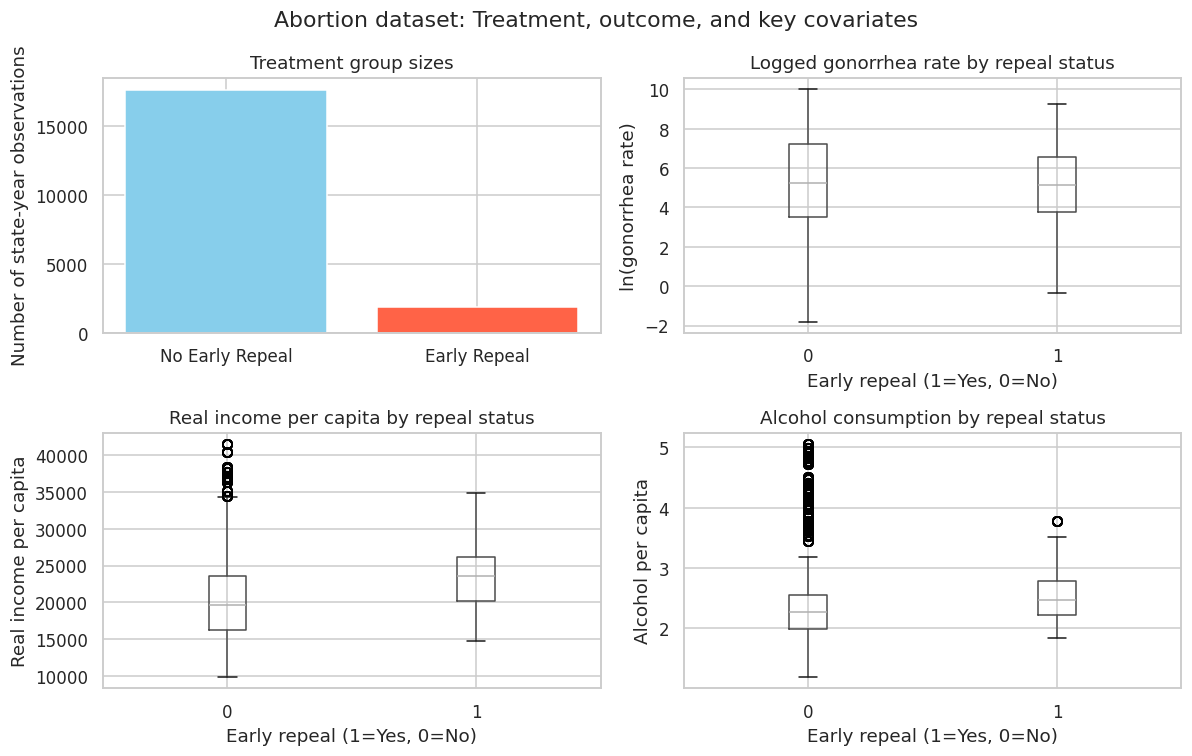

In [39]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(11, 7))

# 1. Treatment group sizes (early repeal vs not)
counts = abortion_df.loc[:, abortion_df.columns.str.lower() == "repeal"].squeeze().value_counts().sort_index()
axes[0, 0].bar(["No Early Repeal", "Early Repeal"], counts.to_numpy(), color=["skyblue", "tomato"])
axes[0, 0].set_title("Treatment group sizes")
axes[0, 0].set_ylabel("Number of state-year observations")

# 2. Outcome by treatment (lnr)
abortion_df.boxplot(column="lnr", by="repeal", ax=axes[0, 1])
axes[0, 1].set_title("Logged gonorrhea rate by repeal status")
axes[0, 1].set_xlabel("Early repeal (1=Yes, 0=No)")
axes[0, 1].set_ylabel("ln(gonorrhea rate)")

plt.suptitle("")

# 3. Real income per capita by treatment
abortion_df.boxplot(column="income", by="repeal", ax=axes[1, 0])
axes[1, 0].set_title("Real income per capita by repeal status")
axes[1, 0].set_xlabel("Early repeal (1=Yes, 0=No)")
axes[1, 0].set_ylabel("Real income per capita")

# 4. Alcohol consumption per capita by treatment
abortion_df.boxplot(column="alcohol", by="repeal", ax=axes[1, 1])
axes[1, 1].set_title("Alcohol consumption by repeal status")
axes[1, 1].set_xlabel("Early repeal (1=Yes, 0=No)")
axes[1, 1].set_ylabel("Alcohol per capita")

plt.suptitle("Abortion dataset: Treatment, outcome, and key covariates")
fig.tight_layout()
plt.show()


### Data Processing for Causal Tree


In [40]:
feature_names = abortion_df.columns.drop(['lnr', 'repeal'])
X = abortion_df[feature_names].to_numpy()
Y = abortion_df['lnr'].to_numpy()
W = abortion_df['repeal'].to_numpy()
# Optionally, drop near-zero-variance columns:
keep = X.var(axis=0) > 1e-10
X = X[:, keep]
feature_names = [name for name, flag in zip(feature_names, keep) if flag]
print("Covariates used:", feature_names)
print("n =", len(Y), " treated =", int(W.sum()))


Covariates used: ['fip', 'age', 'race', 'year', 'sex', 'totpop', 'ir', 'crack', 'alcohol', 'income', 'ur', 'poverty', 'acc', 'wht', 'male', 't', 'younger', 'pi', 'bf15']
n = 19584  treated = 1920


### Split Data into Training and Test Sets

80% training, 20% test.


In [41]:
rng_abortion = np.random.default_rng(42)
n = len(Y)
train_idx = rng_abortion.choice(n, size=round(0.8 * n), replace=False)
test_idx = np.setdiff1d(np.arange(n), train_idx)
X_train, X_test = X[train_idx], X[test_idx]
Y_train, Y_test = Y[train_idx], Y[test_idx]
W_train, W_test = W[train_idx], W[test_idx]
print("Training set size:", len(Y_train))
print("Test set size:", len(Y_test))


Training set size: 15667
Test set size: 3917


### Build Training Data Frame for Causal Tree


In [42]:
df = pd.DataFrame(X_train, columns=feature_names)
df["outcome"] = Y_train
df["treatment"] = W_train
print(df["treatment"].value_counts())
print(df["treatment"].value_counts(normalize=True).round(3))


treatment
0    14118
1     1549
Name: count, dtype: int64
treatment
0    0.901
1    0.099
Name: proportion, dtype: float64


### Fitting a Causal Tree


In [45]:
# Fit a causal tree on the abortion dataset
ct_model_abortion = CausalTree(min_samples_leaf=15, max_depth=4, honest=True, random_state=2024)
# Remove rows with NaN or infinite in 'outcome' before fitting
df_clean = df[np.isfinite(df["outcome"])]
ct_model_abortion.fit(
    df_clean[feature_names].to_numpy(),
    df_clean["treatment"].to_numpy(),
    df_clean["outcome"].to_numpy(),
    feature_names=feature_names,
)
print("Leaves (abortion data):", len(ct_model_abortion.rules()))
print(pd.DataFrame(ct_model_abortion.rules()).round(3))


Leaves (abortion data): 15
     cate     n                                         conditions
0  -0.138   422  poverty <= 12.900 AND ir <= 150.374 AND alcoho...
1  -0.447   202  poverty <= 12.900 AND ir <= 150.374 AND alcoho...
2  -0.827   237  poverty <= 12.900 AND ir <= 150.374 AND alcoho...
3   0.455   969  poverty <= 12.900 AND ir <= 150.374 AND alcoho...
4  -0.542  1184  poverty <= 12.900 AND ir > 150.374 AND totpop ...
5  -1.220   572  poverty <= 12.900 AND ir > 150.374 AND totpop ...
6   1.996    99  poverty <= 12.900 AND ir > 150.374 AND totpop ...
7  -0.445   355  poverty <= 12.900 AND ir > 150.374 AND totpop ...
8   2.416  1109  poverty > 12.900 AND acc <= 16.323 AND totpop ...
9   0.879   182  poverty > 12.900 AND acc <= 16.323 AND totpop ...
10  0.413    92  poverty > 12.900 AND acc <= 16.323 AND totpop ...
11 -0.904   137  poverty > 12.900 AND acc > 16.323 AND totpop <...
12 -2.343   613  poverty > 12.900 AND acc > 16.323 AND totpop <...
13  1.440   710  poverty > 12.900 A

### Key parameters

| Parameter | Purpose | Value used here |
|---|---|---|
| `honest=True` | Split structure and leaf effects on different rows | Always on |
| `min_samples_leaf` | Minimum rows in a child node | 15–20 |
| `max_depth` | Maximum tree depth | 4 |

`fit(X, treatment, y)` holds out the estimation sample when `honest=True`.

## Visualization and interpretation

### Tree plot


Terminal leaves: 15


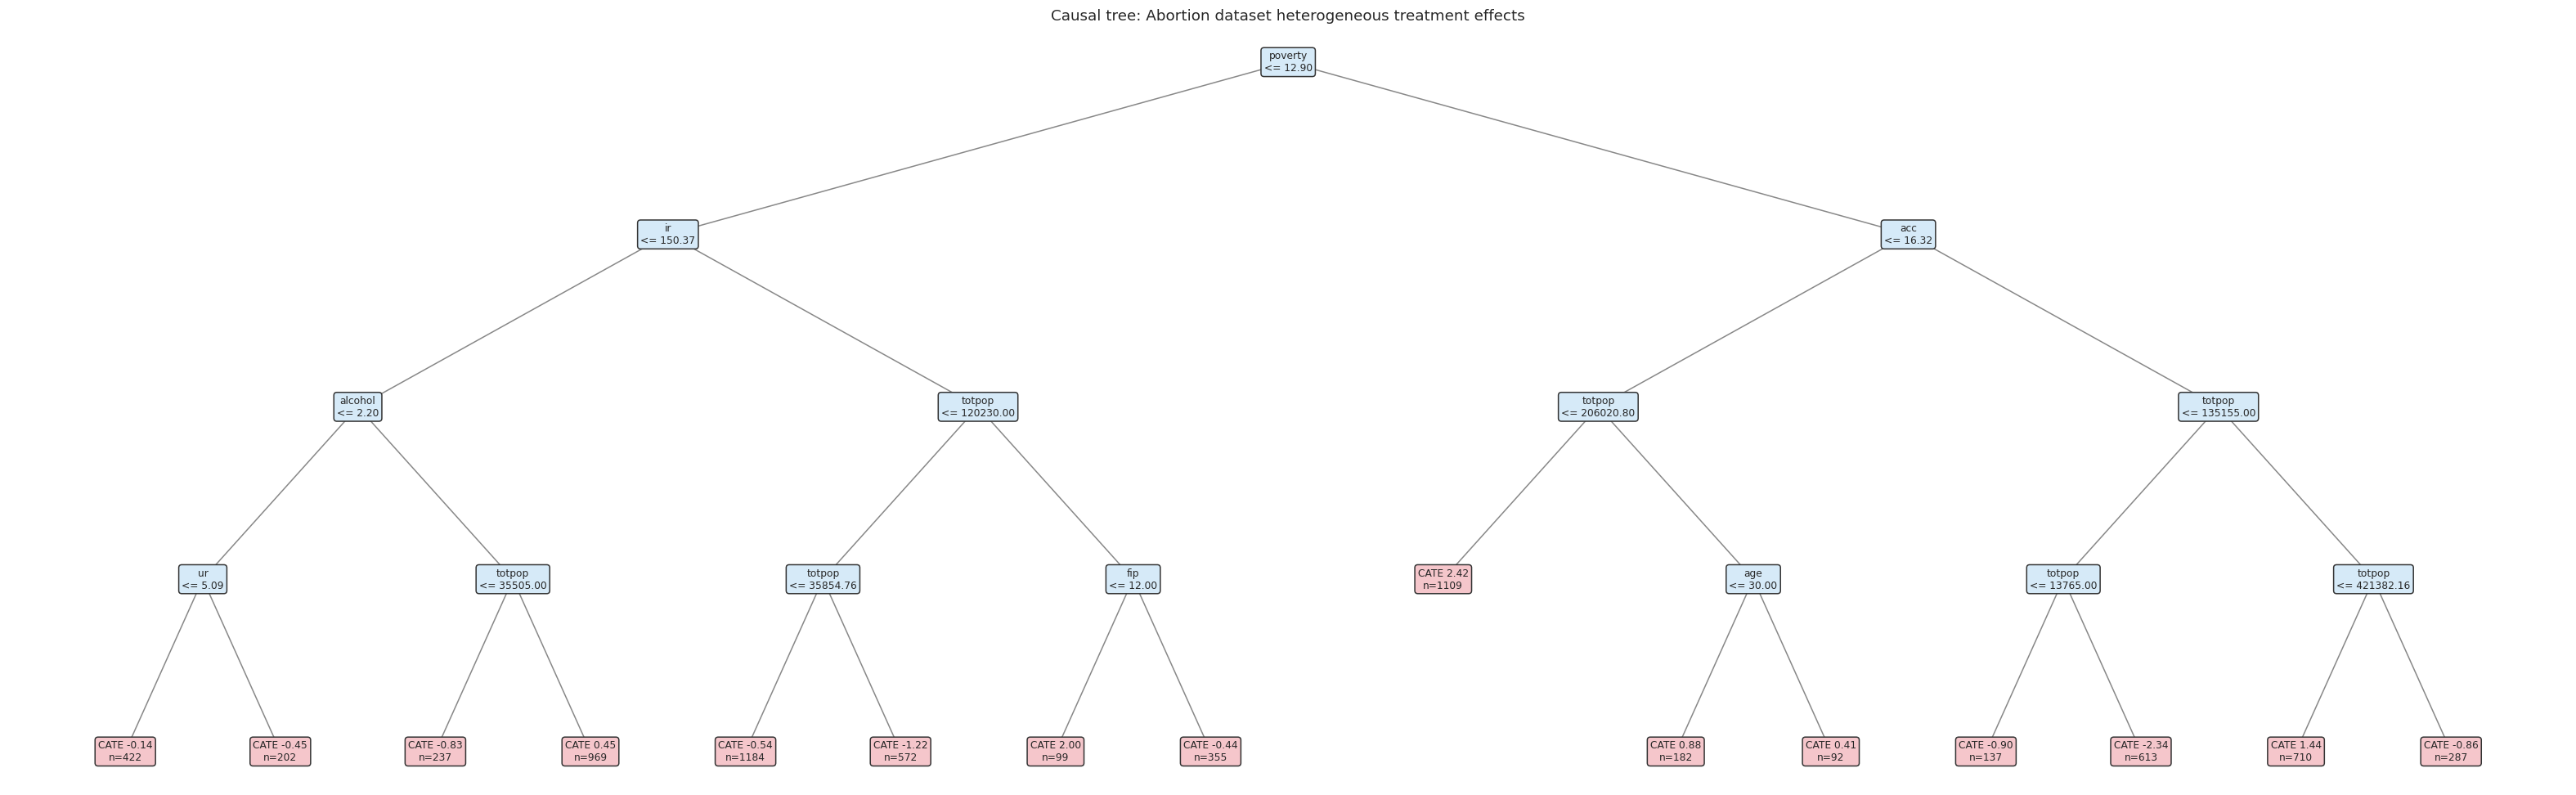

In [48]:
n_leaves = len(ct_model_abortion.rules())
print("Terminal leaves:", n_leaves)
plot_causal_tree(ct_model_abortion, title="Causal tree: Abortion dataset heterogeneous treatment effects")
plt.show()


## Extracting Subgroup Rules

### Extract All Leaf Rules


In [49]:
leaf_rules_abortion = pd.DataFrame(ct_model_abortion.rules())
print("All leaf rules (CATE from the estimation sample, abortion data):")
print(leaf_rules_abortion.round(3).to_string(index=False))
notable_abortion = leaf_rules_abortion[leaf_rules_abortion["cate"].abs() > 1]
print("\nLeaves with |CATE| > 1 (abortion data):")
print(notable_abortion.round(3).to_string(index=False) if len(notable_abortion) else "None")


All leaf rules (CATE from the estimation sample, abortion data):
  cate    n                                                                          conditions
-0.138  422            poverty <= 12.900 AND ir <= 150.374 AND alcohol <= 2.200 AND ur <= 5.092
-0.447  202             poverty <= 12.900 AND ir <= 150.374 AND alcohol <= 2.200 AND ur > 5.092
-0.827  237     poverty <= 12.900 AND ir <= 150.374 AND alcohol > 2.200 AND totpop <= 35505.000
 0.455  969      poverty <= 12.900 AND ir <= 150.374 AND alcohol > 2.200 AND totpop > 35505.000
-0.542 1184 poverty <= 12.900 AND ir > 150.374 AND totpop <= 120230.000 AND totpop <= 35854.760
-1.220  572  poverty <= 12.900 AND ir > 150.374 AND totpop <= 120230.000 AND totpop > 35854.760
 1.996   99        poverty <= 12.900 AND ir > 150.374 AND totpop > 120230.000 AND fip <= 12.000
-0.445  355         poverty <= 12.900 AND ir > 150.374 AND totpop > 120230.000 AND fip > 12.000
 2.416 1109                         poverty > 12.900 AND acc <= 16.323 

### Find Subgroups with Positive Treatment Effects


In [51]:
df_abortion = df.copy()
df_abortion["cate_est"] = ct_model_abortion.predict(df_abortion[feature_names].to_numpy())
df_abortion["leaf_id"] = pd.factorize(np.round(df_abortion["cate_est"].to_numpy(), 6))[0]
if df_abortion["cate_est"].notna().sum() == 0:
    print("No CATE estimates available.")
else:
    positive = df_abortion[df_abortion["cate_est"] > 0]
    summary_cols = ["cate_est", "treatment", *feature_names[:6]]
    if len(positive):
        print("Observations with a positive predicted CATE (abortion data):")
        print(positive[summary_cols].mean(numeric_only=True).round(3))
        print("n =", len(positive))
    else:
        print("No positive predicted CATE (abortion data). Overall training summary:")
        print(df_abortion[summary_cols].mean(numeric_only=True).round(3))
   


Observations with a positive predicted CATE (abortion data):
cate_est          1.500
treatment         0.072
fip              28.700
age              27.571
race              1.328
year           1991.160
sex               1.501
totpop       180885.280
dtype: float64
n = 6923


#### Cross-Validation Error Plot


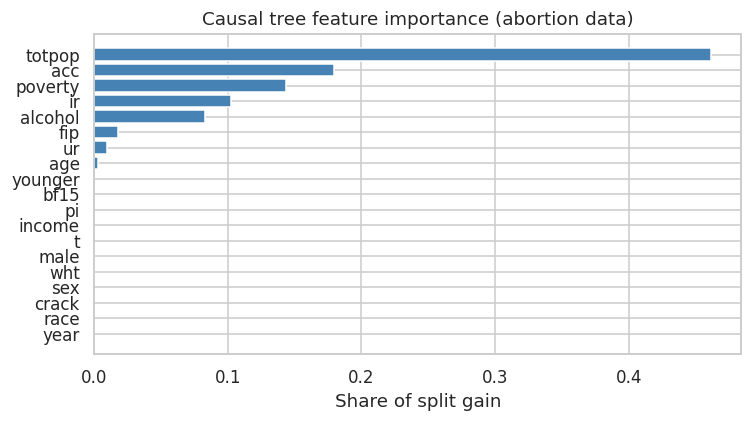

In [52]:
imp = ct_model_abortion.feature_importance()
order = np.argsort(imp)
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(np.array(feature_names)[order], imp[order], color="steelblue")
ax.set_xlabel("Share of split gain")
ax.set_title("Causal tree feature importance (abortion data)")
fig.tight_layout()
plt.show()


#### Test for Heterogeneity

Is there evidence that treatment effects truly vary across subgroups?


In [53]:
obs_var_ab = df_abortion["cate_est"].var()
print("Observed variance of CATE estimates (abortion data):", round(obs_var_ab, 4))
perm_vars_ab = []
for i in range(100):
    w_perm = rng_abortion.permutation(df_abortion["treatment"].to_numpy())
    leaf_cate = []
    for _, part in df_abortion.assign(treatment=w_perm).groupby("leaf_id"):
        leaf_cate.append(
            part.loc[part["treatment"] == 1, "outcome"].mean()
            - part.loc[part["treatment"] == 0, "outcome"].mean()
        )
    perm_vars_ab.append(np.nanvar(leaf_cate))
p_value_ab = float(np.mean(np.asarray(perm_vars_ab) >= obs_var_ab))
print("Permutation p-value for CATE heterogeneity (abortion data):", round(p_value_ab, 3))


Observed variance of CATE estimates (abortion data): 1.9791
Permutation p-value for CATE heterogeneity (abortion data): 0.0


### Leaf treatment effects


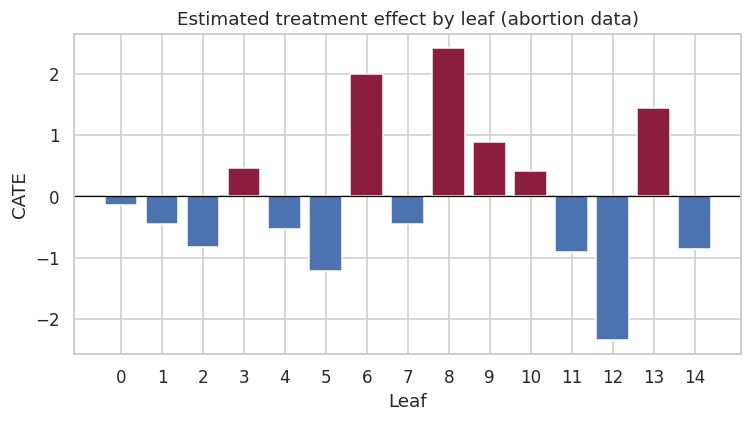

In [55]:
leaf_data_ab = pd.DataFrame(ct_model_abortion.rules())
fig, ax = plt.subplots(figsize=(7, 4))
colors = np.where(leaf_data_ab["cate"] >= 0, "#8B1E3F", "#4C72B0")
ax.bar(leaf_data_ab.index.astype(str), leaf_data_ab["cate"], color=colors)
ax.axhline(0, color="black", lw=0.8)
ax.set_xlabel("Leaf")
ax.set_ylabel("CATE")
ax.set_title("Estimated treatment effect by leaf (abortion data)")
fig.tight_layout()
plt.show()


### How to Interpret the Tree

**Example leaf interpretation**:
```
Node 5: age ≤ 17 AND crack < 0.5
├─ n ≈ 1200 observations
├─ Treatment effect: +0.18 log points (~20% higher gonorrhea rate)
├─ Interpretation: In younger teens with low crack index, early repeal is associated
   with higher risky behavior (proxied by gonorrhea incidence).
```

## Compact SHAP analysis


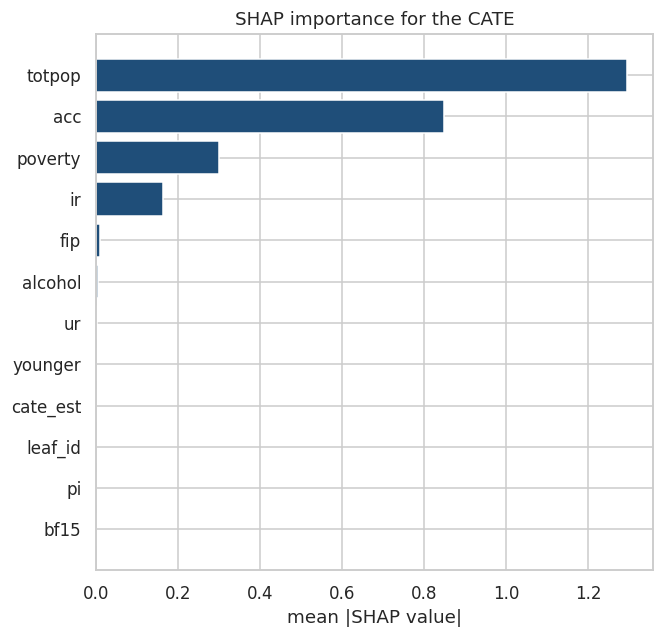

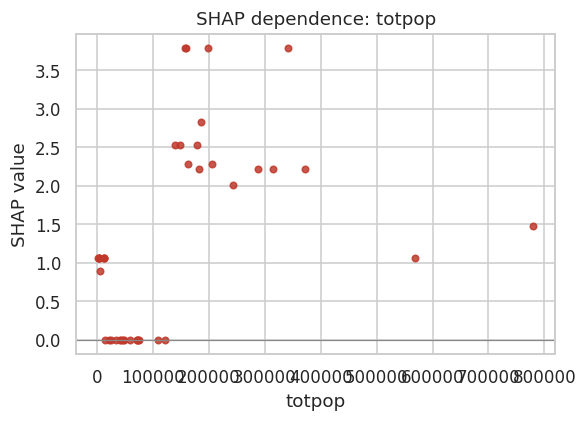

In [60]:
# Define feature_names_ab based on the features used to fit ct_model_abortion
# Assuming ct_model_abortion was fit on df_abortion with specific columns.
# If unsure, you can infer from earlier code. Typically something like:
feature_names_ab = [
    col for col in df_abortion.columns 
    if col not in ('outcome', 'treatment', 'group', 'fold')
]

# Pass feature_names explicitly to avoid ValueError
sv_ab = ct_model_abortion.explain(
    df_abortion[feature_names_ab].to_numpy(),
    max_samples=40,
    random_state=2024,
    feature_names=feature_names_ab,  # added for shape consistency
)
sv_ab.plot_importance(max_display=12)
plt.show()
top_ab = feature_names_ab[int(np.argmax(sv_ab.importance()))]
sv_ab.plot_dependence(top_ab)
plt.show()


## Summary and Conclusion

Causal trees are a powerful tool for uncovering treatment effect heterogeneity in observational data. By recursively partitioning the data based on covariates, they identify subgroups where the effect of a treatment (like abortion legalization) on an outcome (like gonorrhea rates) differs. The honest estimation approach ensures that subgroup-specific treatment effect estimates are unbiased and credible. This allows researchers to understand which populations are most affected by the policy and to generate hypotheses about underlying mechanisms. This tutorial demonstrated how to fit a causal tree using `CausalTree`, interpret the resulting tree structure, and validate findings with permutation tests for heterogeneity. While single trees are interpretable, they can be unstable in small samples or with many covariates. For more robust detection of heterogeneity, consider using causal forests or other ensemble methods. Always validate balance within leaves and interpret findings cautiously, especially in observational policy data where unmeasured confounding may be present.

## Resources

- Athey & Imbens (2016). *Recursive Partitioning for Heterogeneous Causal Effects*. PNAS.
- The Effect (Huntington-Klein): https://theeffectbook.net
